Max diff between manual and Keras hidden states: 7.750859509769725e-08


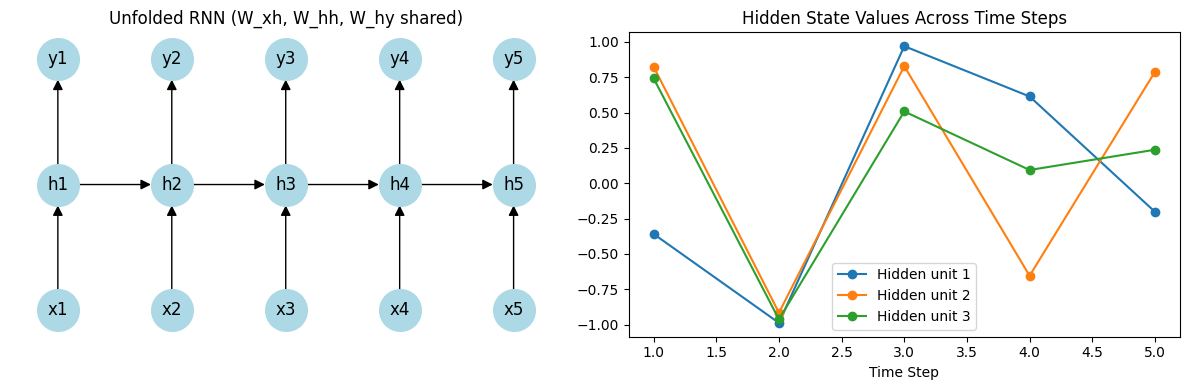

In [4]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

seq_len, feat_dim, units = 5, 4, 3
X = np.random.randn(1, seq_len, feat_dim).astype(np.float32)

rnn_layer = layers.SimpleRNN(units, activation="tanh", return_sequences=True)
model = models.Sequential([layers.Input(shape=(seq_len, feat_dim)), rnn_layer])
keras_h = model.predict(X, verbose=0)[0]

W_xh, W_hh, b_h = rnn_layer.get_weights()
h_manual = np.zeros((seq_len, units))
h_prev = np.zeros(units)
for t in range(seq_len):
    h_prev = np.tanh(X[0, t] @ W_xh + h_prev @ W_hh + b_h)
    h_manual[t] = h_prev

print("Max diff between manual and Keras hidden states:", np.max(np.abs(keras_h - h_manual)))

G = nx.DiGraph()
pos = {}
for t in range(seq_len):
    x_node, h_node, y_node = f"x{t+1}", f"h{t+1}", f"y{t+1}"
    G.add_edges_from([(x_node, h_node), (h_node, y_node)])
    pos[x_node] = (t, 0); pos[h_node] = (t, 1); pos[y_node] = (t, 2)
    if t > 0:
        G.add_edge(f"h{t}", h_node)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
nx.draw(G, pos, ax=axes[0], with_labels=True, node_color="lightblue", node_size=900, arrowsize=15)
axes[0].set_title("Unfolded RNN (W_xh, W_hh, W_hy shared)")

for u in range(units):
    axes[1].plot(range(1, seq_len + 1), keras_h[:, u], marker="o", label=f"Hidden unit {u+1}")
axes[1].set_title("Hidden State Values Across Time Steps")
axes[1].set_xlabel("Time Step"); axes[1].legend()
plt.tight_layout(); plt.show()